# LeNet

![Структура AlexNet](lenet5.svg)

In [6]:
# ! pip install Pillow
# ! pip install torchvision

In [7]:
import torch.nn as nn
import torch
from typing import Callable
from torch.utils.data import TensorDataset
from data_utils import images_to_tensor, train_dataset_split, create_dataloader

## Работа с данными

In [ ]:
X_train, y_train = images_to_tensor('../data/trainLabels.csv', '../data/train', channels=3)

Создаём Dataset который умеет выдавать по одному значению, он используется в DataLoader

In [10]:
ds_train = TensorDataset(X_train, y_train)

Разобъём train на tain и val с помощью `train_dataset_split` из из data_utils

In [11]:
ds_train, ds_val = train_dataset_split(ds_train, train_size=0.8)

In [12]:
BATCH_SIZE = 128

Создаём DataLoader для train и val, которые будут выдавать наши пары (картинка, класс) батчами  при обучении

In [13]:
dl_train = create_dataloader(ds_train, BATCH_SIZE, shuffle=True)
dl_val = create_dataloader(ds_val, BATCH_SIZE, shuffle=False)

## Создание класса LeNet

Этот класс предназначен для создания нейросетей, архитектура повторяет каноничный LeNet с некоторыми упрощениями.

In [14]:
class LeNet5(nn.Module):
    """Упрощённая адаптация LeNet-5 для изображений CIFAR-10 размером 32x32."""

    def __init__(self,
                 in_channels: int = 3,
                 output_size: int = 10):

        super().__init__()

        modules = []
        conv_layers = [6, 16, 120]

        in_ = in_channels # количество входных каналов для свёртки
        for i in range(len(conv_layers)): # цикл добавления свёрточных слоёв, 1 слой - (свёртка + активация + пуллинг)

            # свёртка
            modules.append(nn.Conv2d(
                in_channels=in_,
                out_channels=conv_layers[i],
                kernel_size=5,
                stride=1,
                padding=0,
                ))
            in_ = conv_layers[i]

            modules.append(nn.Tanh()) # слой активации после какждой свёртки

            if i != len(conv_layers)-1: # после каждой свёртки кроме последней добавляем слой пулинга
                modules.append(nn.AvgPool2d(kernel_size=2, stride=2))

        # после всех свёрточных слоёв распрямляем значения в вектор, чтобы подать на вход линейному слою
        modules.append(nn.Flatten())

        # линейный слой на 84 нейрона
        modules.append(nn.Linear(120, 84))
        modules.append(nn.Tanh())

        # в конце добавляем выходной слой, дающий предсказания (логиты) для каждого из классов
        modules.append(nn.Linear(84, output_size))

        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)

In [ ]:
DEVICE = DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps")

In [16]:
lenet5 = LeNet5().to(DEVICE)
loss_func = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(lenet5.parameters(), lr=1e-4)

## Обучение

In [17]:
from train_utils import train

Создадим универсальный метод для обучения любой нейросети

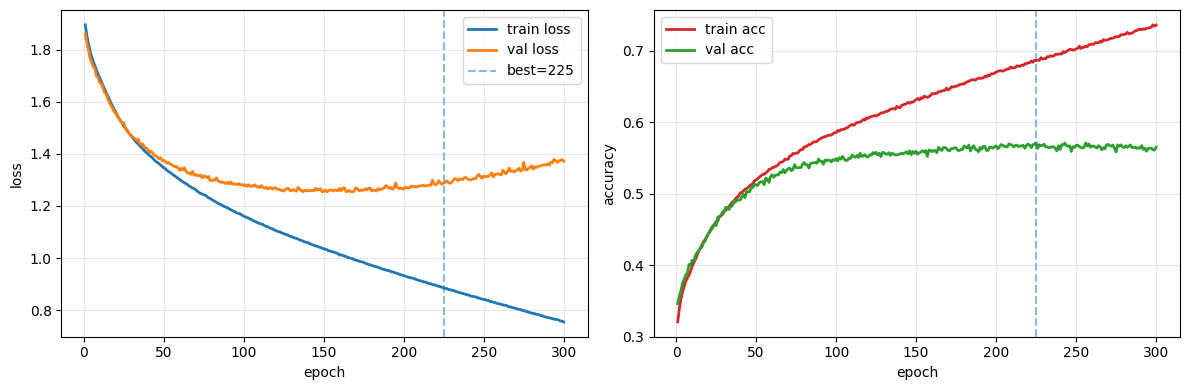

Best epoch = 225, best val_acc = 0.5711


,0
0,0.5711
1,225.0000


In [ ]:
train(lenet5, optimizer, loss_func, dl_train, dl_val, "../models/lenet5.pth", DEVICE, EPOCH_COUNT=300)

## Итог

В ходе работы была реализована и обучена адаптированная архитектура **LeNet-5** для классификации изображений датасета CIFAR-10. Максимальная точность на валидационной выборке составила **57,11 %** и была достигнута на 225-й эпохе.

Результат объясняется особенностями архитектуры, предложенной в 1998 году преимущественно для распознавания рукописных символов. По сравнению с более современными сетями LeNet-5 имеет относительно простую структуру и ограниченные возможности извлечения сложных признаков, необходимых для классификации цветных изображений. Тем не менее для архитектуры своего времени LeNet-5 стала значимым достижением и продемонстрировала применимость свёрточных нейронных сетей к задачам распознавания изображений.
